# Controlling the final approach

Every maneuver of the previous notebooks was computed in advance and then executed: a burn, a coast, another burn. That is how the far part of a rendezvous is flown, and it stops working near the target. Over the last hundreds of metres the errors of navigation and of execution are no longer small compared with the distances involved, and the deputy cannot be on a trajectory that is only correct if everything goes as planned. The motion has to be corrected continuously, from the measured state: it needs feedback.

This notebook builds the controllers that the closed-loop simulation uses, on the linear model alone, where the behaviour of each one can be seen without sensors, navigation or nonlinear dynamics in the way. It starts from the relative motion written as a linear system, designs a regulator that holds a point, flies a straight-line approach and measures what it costs, shows what a regulator cannot do and a predictive controller can, turns the commanded force into thruster pulses, and closes with the attitude control law and the limits of the reaction wheels.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.constants import J2_EARTH, MU_EARTH, OMEGA_EARTH, R_EARTH
from ios_mission_planner.dynamics.attitude.quaternion import (
    quaternion_error, quaternion_multiply, quaternion_to_rotation_vector, rotation_vector_to_quaternion,
)
from ios_mission_planner.dynamics.relative.cw import cw_discrete_matrices, cw_system_matrices
from ios_mission_planner.gnc.actuators import ReactionWheels, ThrusterSet
from ios_mission_planner.gnc.control import (
    ApproachMPC, HoldController, attitude_gains, cw_feedforward_acceleration, dlqr,
    quaternion_feedback_torque, tracking_weights,
)
from ios_mission_planner.gnc.guidance import GlideslopeReference
from ios_mission_planner.sim.truth import TruthModel

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

RADIUS = R_EARTH + 500.0
N = np.sqrt(MU_EARTH / RADIUS**3)
PERIOD = 2 * np.pi / N
MASS = 160.0
A_MAX = 2.0 / MASS          # acceleration of a 2 N thruster on a 160 kg deputy [m/s^2]

## The relative motion as a linear system

The Clohessy-Wiltshire equations are linear, so they can be written as $\dot{\boldsymbol x} = A\boldsymbol x + B\boldsymbol u$, with the state $\boldsymbol x$ made of relative position and velocity and the input $\boldsymbol u$ the acceleration given by the thrusters. A digital controller changes its command at fixed instants and holds it in between, so what it needs is the discrete form $\boldsymbol x_{k+1} = \Phi\boldsymbol x_k + \Gamma\boldsymbol u_k$, exact for an input held constant over the step. `cw_system_matrices` and `cw_discrete_matrices` return the two forms.

The first thing the model says is where the deputy can stay without thrust. A point at rest anywhere on the V-bar is an equilibrium, which is why hold points are placed there. A point at rest anywhere else is not: holding it requires a constant acceleration, and `cw_feedforward_acceleration` computes how much.

on the V-bar, 100 m behind: acceleration to stay [0. 0. 0.] um/s^2, 0.000 m/s per orbit
on the R-bar, 100 m below: acceleration to stay [367.49   0.     0.  ] um/s^2, 2.086 m/s per orbit


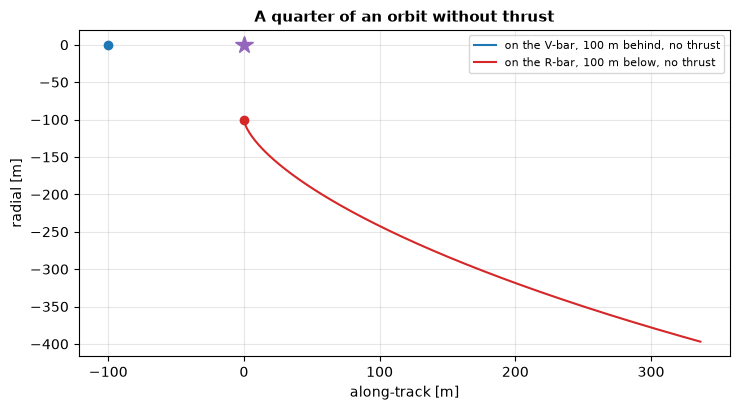

In [2]:
phi, gamma = cw_discrete_matrices(10.0, N)
steps = int(PERIOD / 10.0)

points = {"on the V-bar, 100 m behind": np.array([0.0, -100.0, 0.0]),
          "on the R-bar, 100 m below": np.array([-100.0, 0.0, 0.0])}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (name, point), color in zip(points.items(), (COL_ANA, COL_NUM)):
    state = np.concatenate([point, np.zeros(3)])
    path = [state]
    for _ in range(steps // 4):
        state = phi @ state
        path.append(state)
    path = np.array(path)
    ax.plot(path[:, 1], path[:, 0], color=color, label=f"{name}, no thrust")
    ax.plot(point[1], point[0], "o", color=color)

    hold = cw_feedforward_acceleration(N, point, np.zeros(3))
    print(f"{name}: acceleration to stay {np.round(hold * 1e6, 2)} um/s^2, "
          f"{np.linalg.norm(hold) * PERIOD:.3f} m/s per orbit")
ax.plot(0, 0, "*", color=COL_ZONE, ms=13)
ax.set_xlabel("along-track [m]"); ax.set_ylabel("radial [m]")
ax.set_title("A quarter of an orbit without thrust")
ax.legend(fontsize=8)
fig.tight_layout()

The point on the V-bar stays where it is and needs no thrust. The point 100 m below the chief starts to fall and then moves ahead: at rest in the frame of the chief it turns around the Earth at the angular rate of the chief but at a smaller radius, which is too slow for an orbit at that radius. Keeping it in place takes a constant radial acceleration $3n^2x$, 0.37 mm/s$^2$, which adds up to more than 2 m/s per orbit. This is why the hold points of the approach are on the V-bar, and why waiting on the R-bar is paid in propellant.

## Holding a point: the linear quadratic regulator

An equilibrium is not stable: a deputy left near a V-bar point with a small radial error drifts away. A state feedback $\boldsymbol u = -K(\boldsymbol x - \boldsymbol x_{ref})$ brings it back, and the linear quadratic regulator chooses the gain $K$ that minimizes

$$
J = \sum_k \left(\boldsymbol x_k - \boldsymbol x_{ref}\right)^{\mathsf T} Q \left(\boldsymbol x_k - \boldsymbol x_{ref}\right) + \boldsymbol u_k^{\mathsf T} R\, \boldsymbol u_k ,
$$

a compromise between how far the state is from the reference and how much thrust is used. The weights are set here by Bryson's rule: each quantity is divided by the deviation considered acceptable, so that $Q$ and $R$ say, in physical units, how tightly the point must be held and how hard the thrusters may work for it. The plot compares a loose hold, suited to a far hold point, with a tight one.

position tolerance 5.0 m: slowest time constant   124 s, peak acceleration 1.68 mm/s^2, delta-v 0.254 m/s
position tolerance 0.5 m: slowest time constant    19 s, peak acceleration 49.59 mm/s^2, delta-v 1.466 m/s


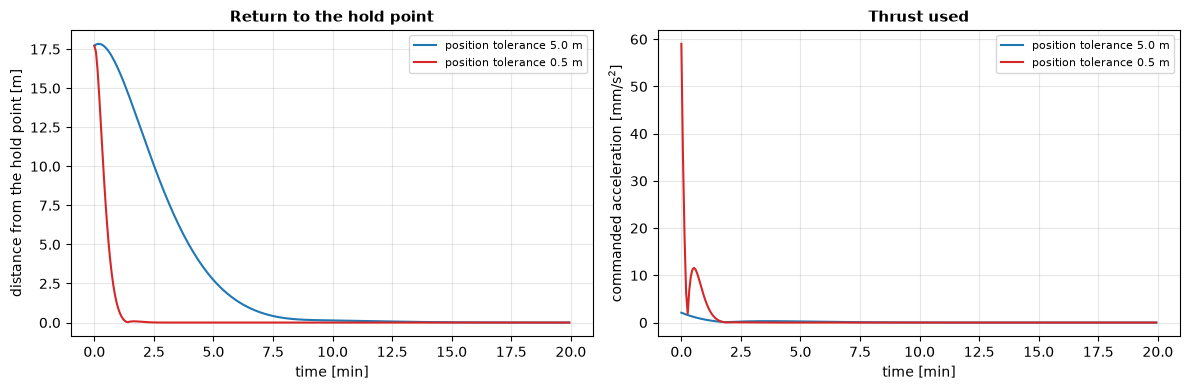

In [3]:
DT = 4.0
phi, gamma = cw_discrete_matrices(DT, N)
reference = np.array([0.0, -500.0, 0.0])
start = np.array([8.0, -515.0, -5.0, 0.01, -0.02, 0.0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (tolerance, scale), color in zip(((5.0, 5e-4), (0.5, 2e-3)), (COL_ANA, COL_NUM)):
    q, r = tracking_weights(tolerance, np.sqrt(scale * tolerance), scale)
    controller = HoldController(N, DT, q, r)
    state, history, spent = start.copy(), [], 0.0
    for _ in range(300):
        u = controller.acceleration(state, reference)
        history.append(np.concatenate([state, u]))
        spent += np.abs(u).sum() * DT
        state = phi @ state + gamma @ u
    history = np.array(history)
    t = np.arange(len(history)) * DT / 60
    label = f"position tolerance {tolerance} m"
    axes[0].plot(t, np.linalg.norm(history[:, :3] - reference, axis=1), color=color, label=label)
    axes[1].plot(t, np.linalg.norm(history[:, 6:], axis=1) * 1e3, color=color, label=label)

    poles = np.linalg.eigvals(phi - gamma @ controller.gain)
    slowest = -DT / np.log(np.abs(poles).max())
    print(f"{label}: slowest time constant {slowest:5.0f} s, peak acceleration "
          f"{np.abs(history[:, 6:]).max() * 1e3:.2f} mm/s^2, delta-v {spent:.3f} m/s")
axes[0].set_xlabel("time [min]"); axes[0].set_ylabel("distance from the hold point [m]")
axes[0].set_title("Return to the hold point"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("time [min]"); axes[1].set_ylabel("commanded acceleration [mm/s$^2$]")
axes[1].set_title("Thrust used"); axes[1].legend(fontsize=8)
fig.tight_layout()

The tolerance sets the speed of the response. With a tolerance of 5 m the slowest mode of the closed loop has a time constant of about two minutes and the command stays below 2 mm/s$^2$. With a tolerance of 0.5 m the response is six times faster, but the same initial error produces a command of 50 mm/s$^2$, four times what the thrusters of the reference deputy can deliver, and costs almost six times the propellant.

A tight hold belongs near the port, where the errors are centimetres. Far away it would spend propellant chasing an error that does no harm, and in the real loop it would also amplify the noise of the navigation, which is largest there. The simulator scales the tolerance of each hold point with its distance from the chief for this reason.

## A forced approach and what it costs

Between the last two hold points the deputy does not coast: it is driven along a straight line on the V-bar, toward the port, at a speed that decreases with the distance still to cover. The reference is a point that moves along the line with the glideslope law $v = \min(v_{max}, \max(v_{min}, d/\tau))$, and the regulator tracks it. `GlideslopeReference` generates that moving point, with a limited acceleration so that it never asks for a step in velocity.

A straight line along the V-bar is not a natural motion. A deputy moving at speed $v$ along the direction of flight feels the Coriolis term $2nv$ in the radial direction, which bends its path. The thrusters must cancel it for as long as the motion lasts, and the feedforward supplies exactly that.

duration 35.4 min; radial delta-v 1.063 m/s (2 n d = 1.063); along-track delta-v 0.790 m/s (2 v_max = 0.8)
total 1.852 m/s for 480 m; the same distance at half the speed would cost 1.463 m/s and take about twice as long


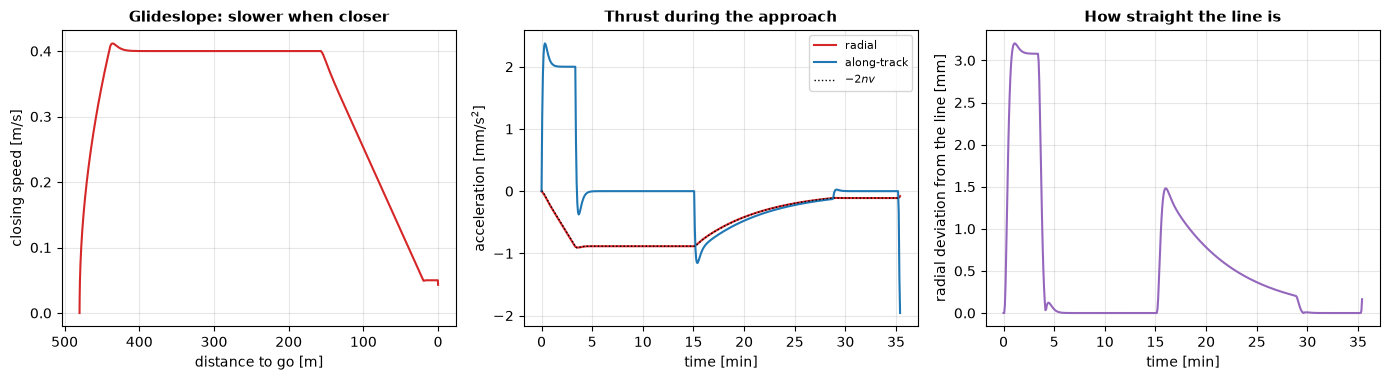

In [4]:
carrot = GlideslopeReference([0.0, -500.0, 0.0], [0.0, -20.0, 0.0], v_max=0.4, v_min=0.05,
                             time_constant=400.0, max_acceleration=0.002)
q, r = tracking_weights(0.5, 0.03, 4e-3)
gain, _ = dlqr(phi, gamma, q, r)

state = np.array([0.0, -500.0, 0.0, 0.0, 0.0, 0.0])
log = []
while not carrot.arrived:
    target = np.concatenate([carrot.position, carrot.velocity])
    feedforward = cw_feedforward_acceleration(N, carrot.position, carrot.velocity)
    u = feedforward - gain @ (state - target)
    log.append(np.concatenate([state, u, [carrot.distance_to_go]]))
    state = phi @ state + gamma @ u
    carrot.advance(DT)
log = np.array(log)
t = np.arange(len(log)) * DT / 60
distance = -20.0 - log[:, 1]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].plot(distance, log[:, 4], color=COL_NUM)
axes[0].invert_xaxis()
axes[0].set_xlabel("distance to go [m]"); axes[0].set_ylabel("closing speed [m/s]")
axes[0].set_title("Glideslope: slower when closer")
axes[1].plot(t, log[:, 6] * 1e3, color=COL_NUM, label="radial")
axes[1].plot(t, log[:, 7] * 1e3, color=COL_ANA, label="along-track")
axes[1].plot(t, -2 * N * log[:, 4] * 1e3, "k:", lw=1, label="$-2nv$")
axes[1].set_xlabel("time [min]"); axes[1].set_ylabel("acceleration [mm/s$^2$]")
axes[1].set_title("Thrust during the approach"); axes[1].legend(fontsize=8)
axes[2].plot(t, np.abs(log[:, 0]) * 1e3, color=COL_ZONE)
axes[2].set_xlabel("time [min]"); axes[2].set_ylabel("radial deviation from the line [mm]")
axes[2].set_title("How straight the line is")
fig.tight_layout()

radial = np.abs(log[:, 6]).sum() * DT
along = np.abs(log[:, 7]).sum() * DT
print(f"duration {t[-1]:.1f} min; radial delta-v {radial:.3f} m/s (2 n d = {2 * N * 480:.3f}); "
      f"along-track delta-v {along:.3f} m/s (2 v_max = {2 * 0.4:.1f})")
print(f"total {radial + along:.3f} m/s for 480 m; the same distance at half the speed would cost "
      f"{2 * N * 480 + 2 * 0.2:.3f} m/s and take about twice as long")

The radial thrust follows $-2nv$, and its integral over the approach is $2nd$, 1.06 m/s for 480 m. It depends on the distance covered and not on the speed, because going slower lowers the acceleration and lengthens the time by the same factor. The along-track thrust is used only to speed up at the start and to slow down along the way, for a total of twice the cruise speed. The speed therefore changes the cost only through this second term: halving it saves 0.4 m/s and doubles the duration.

The deviation from the straight line stays within about 3 mm, and it appears only while the speed is changing. The feedforward does almost all the work, and the feedback corrects the transients.

## Constraints: what a regulator cannot do

The regulator has one rule, proportional to the error, and no notion of a limit. It does not know that the thrusters saturate, that the deputy must stay inside an approach corridor, or that the closing speed must decrease as the target gets nearer. When the error is small none of this matters. When it is large, the regulator asks for more thrust than exists, and the path that results from the clipped command is whatever it happens to be.

A model predictive controller handles the limits explicitly. At each control period it solves an optimization over the next steps, with the same quadratic cost, subject to the dynamics, to the thrust limit and to the constraints on the state; it applies the first command and solves again at the next period. `ApproachMPC` implements it as a quadratic program solved by OSQP. The thrust limit is a hard constraint. The corridor and the closing speed are softened by slack variables with a high price, so that the problem always has a solution even when the state starts outside them.

The test case is a deputy that arrives badly: 80 m from the port, 25 m off the axis and outside the corridor, closing at 0.5 m/s. Both controllers are asked to bring it to the hold point 20 m from the port.

regulator              closest to the port   -3.6 m; time outside the corridor  112 s; largest excess of closing speed 0.771 m/s; delta-v 3.79 m/s
predictive controller  closest to the port   20.0 m; time outside the corridor   48 s; largest excess of closing speed 0.060 m/s; delta-v 2.59 m/s
solver status at the last step: solved


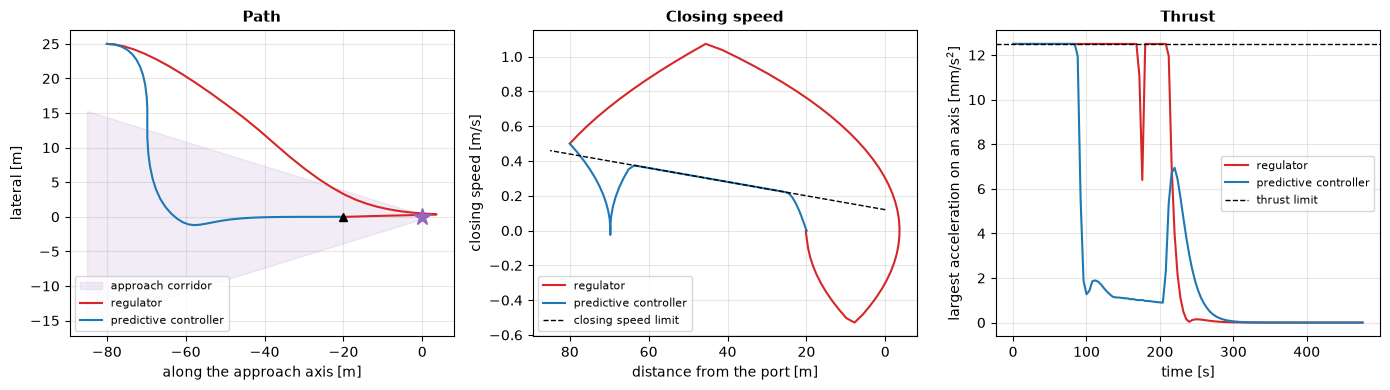

In [5]:
# geometry: approach along +y toward a port at y = 0; hold point 20 m before it
slope = np.tan(np.deg2rad(10.0))
corridor_radius, speed_floor, speed_slope = 0.3, 0.12, 0.004
rows, bounds = [], []
for lateral in (np.array([1.0, 0, 0]), np.array([-1.0, 0, 0]), np.array([0, 0, 1.0]), np.array([0, 0, -1.0])):
    rows.append(np.concatenate([lateral + slope * np.array([0, 1.0, 0]), np.zeros(3)]))   # |lateral| <= r0 + slope * d, d = -y
    bounds.append(corridor_radius)
rows.append(np.array([0, speed_slope, 0, 0, 1.0, 0]))                                       # v_y <= floor + slope_v * d
bounds.append(speed_floor)
constraint_matrix, constraint_bound = np.array(rows), np.array(bounds)

q, r = tracking_weights(0.5, 0.03, 4e-3)
mpc = ApproachMPC(N, DT, 30, q, r, A_MAX, constraint_matrix)
reference = np.tile([0.0, -20.0, 0.0, 0.0, 0.0, 0.0], (31, 1))
start = np.array([25.0, -80.0, 0.0, 0.0, 0.5, 0.0])

def fly(law, steps=120):
    state, history = start.copy(), []
    for _ in range(steps):
        u = law(state)
        history.append(np.concatenate([state, u]))
        state = phi @ state + gamma @ u
    return np.array(history)

regulator = fly(lambda x: np.clip(-mpc.lqr_gain @ (x - reference[0]), -A_MAX, A_MAX))
predictive = fly(lambda x: mpc.solve(x, reference, constraint_bound=constraint_bound))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
d = np.linspace(0, 85, 50)
axes[0].fill_between(-d, -(corridor_radius + slope * d), corridor_radius + slope * d, color=COL_ZONE, alpha=0.12,
                     label="approach corridor")
for history, color, name in ((regulator, COL_NUM, "regulator"), (predictive, COL_ANA, "predictive controller")):
    axes[0].plot(history[:, 1], history[:, 0], color=color, label=name)
    axes[1].plot(-history[:, 1], history[:, 4], color=color, label=name)
    axes[2].plot(np.arange(len(history)) * DT, np.abs(history[:, 6:]).max(axis=1) * 1e3, color=color, label=name)
axes[0].plot(-20, 0, "k^"); axes[0].plot(0, 0, "*", color=COL_ZONE, ms=13)
axes[0].set_xlabel("along the approach axis [m]"); axes[0].set_ylabel("lateral [m]")
axes[0].set_title("Path"); axes[0].legend(fontsize=8, loc="lower left")
axes[1].plot(d, speed_floor + speed_slope * d, "k--", lw=1, label="closing speed limit")
axes[1].invert_xaxis()
axes[1].set_xlabel("distance from the port [m]"); axes[1].set_ylabel("closing speed [m/s]")
axes[1].set_title("Closing speed"); axes[1].legend(fontsize=8)
axes[2].axhline(A_MAX * 1e3, color="k", ls="--", lw=1, label="thrust limit")
axes[2].set_xlabel("time [s]"); axes[2].set_ylabel("largest acceleration on an axis [mm/s$^2$]")
axes[2].set_title("Thrust"); axes[2].legend(fontsize=8)
fig.tight_layout()

for name, history in (("regulator", regulator), ("predictive controller", predictive)):
    distance = -history[:, 1]
    outside = np.abs(history[:, 0]) - (corridor_radius + slope * np.maximum(distance, 0))
    excess = history[:, 4] - (speed_floor + speed_slope * np.maximum(distance, 0))
    print(f"{name:22s} closest to the port {distance.min():6.1f} m; time outside the corridor "
          f"{(outside > 0).sum() * DT:4.0f} s; largest excess of closing speed {max(excess.max(), 0):.3f} m/s; "
          f"delta-v {np.abs(history[:, 6:]).sum() * DT:.2f} m/s")
print(f"solver status at the last step: {mpc.last_status}")

The regulator saturates the thrusters on both axes, and what the clipped command produces is not what it computed. It pulls the deputy toward the axis and toward the hold point at the same time, the closing speed grows beyond 1 m/s, the deputy goes through the hold point, crosses the plane of the port more than 3 m beyond it, and only then comes back. In reality this is a collision.

The predictive controller knows the limits. It brakes and moves sideways first, to get inside the corridor, then closes exactly along the limit on the closing speed, and stops at the hold point. It is outside the corridor for 48 seconds, because it started there, and it exceeds the speed limit only by the 0.06 m/s it started with. It also spends a third less propellant, because it does not build up a speed that it then has to destroy.

## From a commanded force to thruster pulses

The controllers compute an acceleration that can take any value. The thrusters cannot: each is either off or on at its full thrust, and it cannot stay on for less than a minimum time. The product of the thrust and of that minimum time is the minimum impulse bit, the smallest change of momentum the thruster can deliver. `ThrusterSet` models the modulation: on each axis it accumulates the requested impulse and fires when the total reaches the minimum impulse bit, for as long as needed to deliver it. Small requests are not lost, they wait until they add up to a pulse.

The effect shows when the deputy must be held still. With a fine impulse bit the pulses are small and frequent and the position barely moves. With a coarse one the controller can only correct in large steps, and the deputy oscillates around the hold point in a limit cycle whose size is set by the hardware, not by the control law.

impulse bit 0.04 N s (0.25 mm/s)   rms position error   0.03 cm,  1078 pulses, 0.640 m/s per hour
impulse bit 0.4 N s (2.50 mm/s)    rms position error   0.32 cm,  1215 pulses, 7.213 m/s per hour


impulse bit 2.0 N s (12.50 mm/s)   rms position error   1.88 cm,   497 pulses, 12.425 m/s per hour


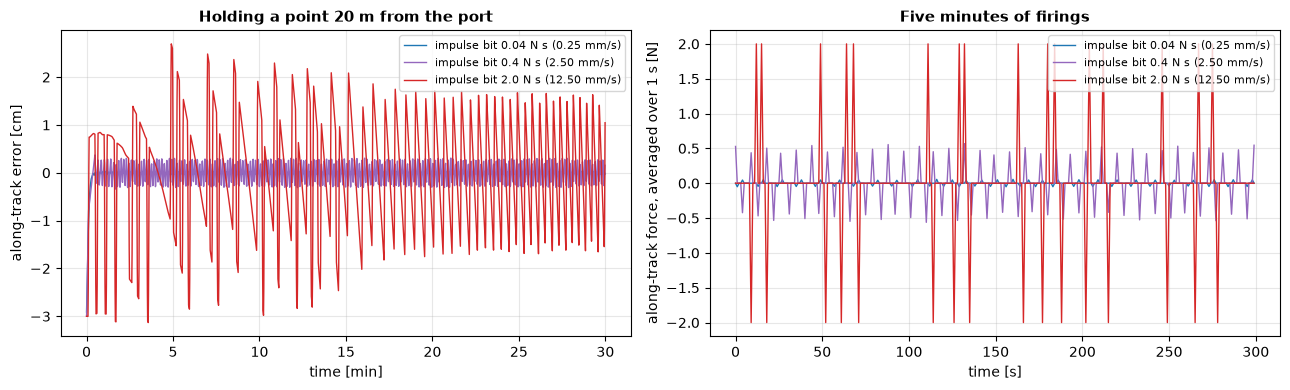

In [6]:
DT1 = 1.0
phi1, gamma1 = cw_discrete_matrices(DT1, N)
q, r = tracking_weights(0.05, 0.01, 4e-3)
gain1, _ = dlqr(phi1, gamma1, q, r)
hold = np.array([0.0, -21.6, 0.0])
disturbance = np.array([2e-6, -1e-6, 1e-6])      # a small constant acceleration, as differential drag would give

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for bit, color in ((0.04, COL_ANA), (0.4, COL_ZONE), (2.0, COL_NUM)):
    thrusters = ThrusterSet(max_force=2.0, isp=220.0, min_impulse_bit=bit)
    state = np.concatenate([hold, np.zeros(3)]) + np.array([0.02, -0.03, 0.01, 0, 0, 0])
    error, force, spent, pulses = [], [], 0.0, 0
    for _ in range(1800):
        u = -gain1 @ (state - np.concatenate([hold, np.zeros(3)]))
        intended, actual, _, _ = thrusters.command(MASS * u, DT1)
        state = phi1 @ state + gamma1 @ (actual / MASS + disturbance)
        error.append(state[:3] - hold); force.append(actual[1])
        spent += np.abs(actual).sum() / MASS * DT1
        pulses += np.count_nonzero(actual)
    error = np.array(error)
    label = f"impulse bit {bit} N s ({bit / MASS * 1e3:.2f} mm/s)"
    axes[0].plot(np.arange(1800) / 60, error[:, 1] * 100, color=color, lw=1, label=label)
    axes[1].plot(np.arange(300), np.array(force)[600:900], color=color, lw=1, label=label)
    print(f"{label:34s} rms position error {np.sqrt((error[300:] ** 2).sum(axis=1).mean()) * 100:6.2f} cm, "
          f"{pulses:5d} pulses, {spent / 0.5:.3f} m/s per hour")
axes[0].set_xlabel("time [min]"); axes[0].set_ylabel("along-track error [cm]")
axes[0].set_title("Holding a point 20 m from the port"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("along-track force, averaged over 1 s [N]")
axes[1].set_title("Five minutes of firings"); axes[1].legend(fontsize=8)
fig.tight_layout()

With the impulse bit of the reference deputy, 0.04 N s, one pulse changes the velocity by a quarter of a millimetre per second and the hold point is kept within a fraction of a millimetre. With an impulse bit ten times larger the error grows tenfold. With 2 N s, the bit of a thruster that cannot fire for less than a second, the deputy swings by about 2 cm around the hold point.

The propellant tells the same story more sharply. The disturbance alone would cost about 0.01 m/s per hour. The fine thrusters spend 0.6 m/s per hour and the coarse ones 7 and 12: almost all of it is the limit cycle, pulses that overshoot and are then undone by pulses in the opposite direction. A tight control law on on-off thrusters pays for its tightness in propellant, which is why holding a point close to the port is expensive, and the minimum impulse bit, more than the thrust level, decides how precisely a spacecraft can be held.

## Attitude: quaternion feedback and the limits of the wheels

The attitude is controlled by reaction wheels with the quaternion feedback law

$$
\boldsymbol\tau = -k_p\,\boldsymbol q_{e} - k_d\left(\boldsymbol\omega - \boldsymbol\omega_{ref}\right) + \boldsymbol\omega\times\left(I\boldsymbol\omega + \boldsymbol h_w\right),
$$

where $\boldsymbol q_e$ is the vector part of the error quaternion, taken with the sign that gives the shorter rotation, and the last term cancels the gyroscopic torque of the body and of the wheels. The gains follow from the natural frequency and the damping ratio wanted for the closed loop.

A wheel has two limits, on the torque of its motor and on the momentum it can store. The second matters for large rotations: turning the body at a rate $\omega$ puts a momentum $I\omega$ in the wheels, and if the law lets the rate grow freely a wide slew drives the wheels into saturation. `quaternion_feedback_torque` therefore limits the proportional term, so that for a large error the body turns at a chosen constant rate. The test is a slew of 120 degrees with the wheels of the reference deputy, flown on the truth model of the simulator, with and without the limit.

no rate limit                  largest rate 1.61 deg/s, largest wheel momentum 0.500 N m s, error below 0.1 deg after 2.6 min, final error 0.0000 deg
slew rate limited to 0.5 deg/s largest rate 0.54 deg/s, largest wheel momentum 0.244 N m s, error below 0.1 deg after 4.4 min, final error 0.0000 deg


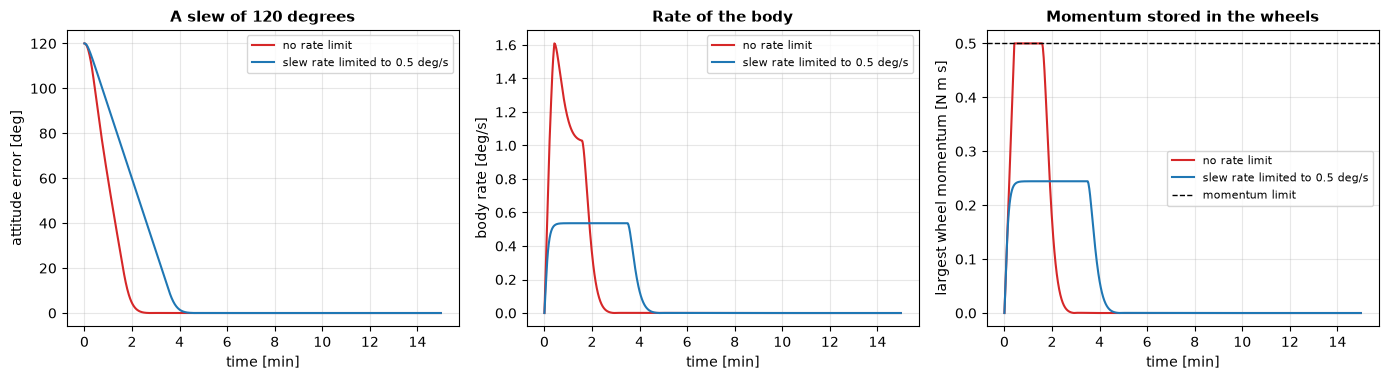

In [7]:
inertia = np.array([22.0, 25.0, 28.0])
kp, kd = attitude_gains(inertia, 0.08, 0.9)
wheels = ReactionWheels(max_torque=0.02, max_momentum=0.5)
speed = np.sqrt(MU_EARTH / RADIUS)
orbit = np.array([RADIUS, 0, 0, 0, speed * np.cos(np.deg2rad(51.6)), speed * np.sin(np.deg2rad(51.6))])

target = np.array([1.0, 0.0, 0.0, 0.0])
start = rotation_vector_to_quaternion(np.deg2rad(120.0) * np.array([0.3, 0.2, 0.93]) / np.linalg.norm([0.3, 0.2, 0.93]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for slew, color, name in ((None, COL_NUM, "no rate limit"), (np.deg2rad(0.5), COL_ANA, "slew rate limited to 0.5 deg/s")):
    truth = TruthModel(MU_EARTH, J2_EARTH, R_EARTH, OMEGA_EARTH, 0.0, RADIUS, 60.0, 0.0, 0.0, inertia,
                       gravity_gradient=False)
    truth.reset(orbit, orbit, MASS, start, np.zeros(3))
    log = []
    for k in range(900):
        q, w, h = truth.quaternion, truth.body_rate, truth.wheel_momentum
        torque = quaternion_feedback_torque(q, w, target, np.zeros(3), inertia, h, kp, kd, slew)
        applied = wheels.command(torque, h, 1.0)
        angle = np.degrees(np.linalg.norm(quaternion_to_rotation_vector(quaternion_error(q, target))))
        log.append([angle, np.degrees(np.linalg.norm(w)), np.abs(h).max(), np.abs(applied).max()])
        truth.set_controls(wheel_torque=applied)
        truth.step(1.0)
    log = np.array(log)
    t = np.arange(900) / 60
    axes[0].plot(t, log[:, 0], color=color, label=name)
    axes[1].plot(t, log[:, 1], color=color, label=name)
    axes[2].plot(t, log[:, 2], color=color, label=name)
    settled = np.argmax(log[:, 0] < 0.1) if (log[:, 0] < 0.1).any() else -1
    print(f"{name:30s} largest rate {log[:, 1].max():.2f} deg/s, largest wheel momentum {log[:, 2].max():.3f} N m s, "
          f"error below 0.1 deg after {settled / 60:.1f} min, final error {log[-1, 0]:.4f} deg")
axes[2].axhline(0.5, color="k", ls="--", lw=1, label="momentum limit")
axes[0].set_ylabel("attitude error [deg]"); axes[0].set_title("A slew of 120 degrees")
axes[1].set_ylabel("body rate [deg/s]"); axes[1].set_title("Rate of the body")
axes[2].set_ylabel("largest wheel momentum [N m s]"); axes[2].set_title("Momentum stored in the wheels")
for ax in axes:
    ax.set_xlabel("time [min]"); ax.legend(fontsize=8)
fig.tight_layout()

Without the limit the body accelerates until the wheels are full: the rate reaches 1.6 degrees per second and the largest wheel sits at its momentum limit of 0.5 N m s for more than a minute. A saturated wheel cannot push further, so during that time the law does not control that axis; the slew ends well here only because nothing else disturbs the body in the meantime. With the rate limited to 0.5 degrees per second the wheels use half of their capacity, the body turns at a constant rate for most of the maneuver, and the slew takes 4.4 minutes instead of 2.6. Both reach the target with no residual error. The simulator uses the limited law.

## Summary

The controllers of the closed-loop simulation are all here, in their simplest setting. `HoldController` keeps the deputy at a hold point with a linear quadratic regulator and the feedforward that makes the point an equilibrium. `GlideslopeReference` produces the reference of a forced approach, whose cost is $2nd$ against the Coriolis acceleration plus twice the cruise speed. `ApproachMPC` tracks that reference while respecting the thrust limit, the approach corridor and a limit on the closing speed, which a regulator cannot do. `ThrusterSet` turns the commanded force into pulses no smaller than the minimum impulse bit, and `quaternion_feedback_torque` with `ReactionWheels` controls the attitude within the torque and the momentum of the wheels.

Everything in this notebook was flown on the linear model with a perfectly known state. The next notebook removes both simplifications: the same controllers fly the nonlinear truth model, and they see the state only through sensors and a navigation filter.